In [14]:
! pip install torch graphviz



  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
Using cached graphviz-0.21-py3-none-any.whl (47 kB)


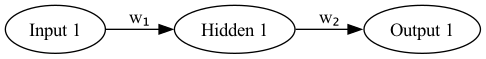

In [24]:
from graphviz import Digraph
from IPython.display import Image, display

dot = Digraph()
dot.attr(rankdir='LR')

# Nodes with labels
dot.node('I1', label='Input 1')
dot.node('H1', label='Hidden 1')
dot.node('O1', label='Output 1')

# Edges with labels
dot.edge('I1', 'H1', label='w₁')
dot.edge('H1', 'O1', label='w₂')

# Display
dot.format = 'png'
filename = dot.render('labeled_network', cleanup=True)
display(Image(filename=filename))


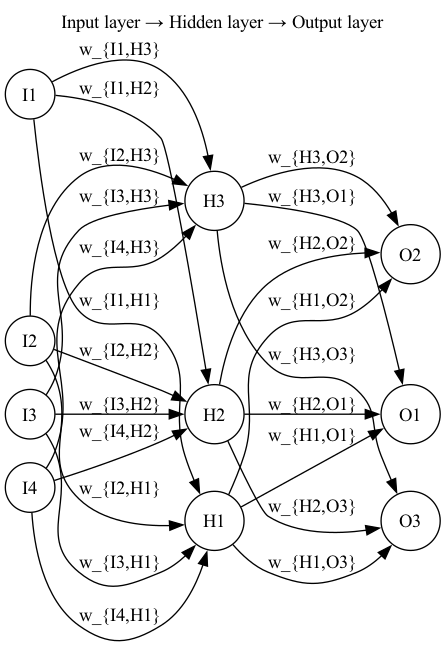

In [22]:
from graphviz import Digraph
from IPython.display import Image, display

dot = Digraph()
dot.attr(rankdir='LR')  # Horizontal layout

# Define nodes
input_nodes = ['I1', 'I2', 'I3', 'I4']
hidden_nodes = ['H1', 'H2', 'H3']
output_nodes = ['O1', 'O2', 'O3']

# Add input nodes with labels
for node in input_nodes:
    dot.node(node, label=node, shape='circle', width='0.5', style='filled', fillcolor='white')

# Add hidden nodes with labels
for node in hidden_nodes:
    dot.node(node, label=node, shape='circle', width='0.5', style='filled', fillcolor='white')

# Add output nodes with labels
for node in output_nodes:
    dot.node(node, label=node, shape='circle', width='0.5', style='filled', fillcolor='white')

# Add edges from input to hidden with weight labels
for i in input_nodes:
    for h in hidden_nodes:
        label = f'w_{{{i},{h}}}'
        dot.edge(i, h, label=label)

# Add edges from hidden to output with weight labels
for h in hidden_nodes:
    for o in output_nodes:
        label = f'w_{{{h},{o}}}'
        dot.edge(h, o, label=label)

# Add layer label
dot.attr(label='Input layer → Hidden layer → Output layer')
dot.attr(labelloc='t', fontsize='14')

# Render and display
dot.format = 'png'
filename = dot.render('neural_net_with_weights', cleanup=True)
display(Image(filename=filename))


In [6]:
import torch

class Perceptron(torch.nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.linear = torch.nn.Linear(input_dim, 1)
        
    def forward(self, x):
        return torch.sigmoid(self.linear(x))


In [8]:
def train(model, train_inputs, train_labels, epochs=100, learning_rate=0.001):
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
    criterion = torch.nn.BCEWithLogitsLoss()
    
    for epoch in range(epochs):
        optimizer.zero_grad()
        output = model(train_inputs)
        loss = criterion(output, train_labels)
        loss.backward()
        optimizer.step()


In [10]:
def test(model, test_inputs, test_labels):
    output = model(test_inputs)
    correct = 0
    for i in range(len(test_labels)):
        if output[i] > 0.5:
            prediction = 1
        else:
            prediction = 0
        if prediction == test_labels[i]:
            correct += 1
    return correct / len(test_labels)


In [12]:
# Define the input and output data
X = torch.Tensor([[0, 0], [0, 1], [1, 0], [1, 1]])
y = torch.Tensor([[0], [1], [1], [0]])

# Create an instance of the Perceptron class
model = Perceptron(2)

# Train the model
train(model, X, y, epochs=1000)

# Test the model
accuracy = test(model, X, y)
print(f'Accuracy: {accuracy:.2f}')


Accuracy: 0.50
